In [1]:
import torch
from torchvision.transforms import transforms
import numpy as np
import ants
import os
from matplotlib import gridspec
import pandas as pd
import pandas as pd 
import numpy as np
import nibabel as nib
import ants
from glob import glob
import torch
import matplotlib.pyplot as plt
import seaborn as sns
# import plotly
# plotly.tools.set_credentials_file(username='Qqin', api_key='GFe6E0uLlZmHtoobrxiv')
# import plotly.plotly as py
# import plotly.graph_objs as go
from inceptionv3 import InceptionAttention3D
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel, f_regression, SelectKBest, SelectPercentile, SelectFwe, \
  f_classif, SelectFdr
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, roc_auc_score, \
average_precision_score, precision_recall_curve, roc_curve, precision_score, recall_score, scorer
from matplotlib.backends.backend_pdf import PdfPages
plt.rc(group={'font': {'size': 'larger'}})
sns.set("paper", font_scale=2.5)
sns.set_style("ticks", {"xtick.major.size": 0,
                        "ytick.major.size": 0,
                        'font.family': ['sans-serif']})
%matplotlib inline

from inceptionv3 import InceptionAttention3D

class SelectP(SelectFdr):
    def __init__(self, score_func, alpha):
        super().__init__(score_func, alpha)

    def _get_support_mask(self):
        return self.pvalues_ <= self.alpha  # similar strategy as STM autism

def specificity_loss_func(ground_truth, predictions):
    tp, tn, fn, fp = 0.0,0.0,0.0,0.0
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return tn/(tn+fp)

def fpr_loss_func(ground_truth, predictions):
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return 1.0*fp/(tn+fp)

def fn_loss_func(ground_truth, predictions):
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return 1.0*fn/(tn+fn)

spec_score = scorer.make_scorer(specificity_loss_func, greater_is_better=True)
#fpr_score = make_scorer(fpr_loss_func, greater_is_better=False)
fpr_score = scorer.make_scorer(fpr_loss_func, greater_is_better=True)

scoring = {'AUC': roc_auc_score, 
           'Accuracy': accuracy_score,
           'PRAUC': average_precision_score,
           "specificity": specificity_loss_func, 
           "FPR": fpr_loss_func,
           "FNR": fn_loss_func,
           'f1': f1_score,
           'recall': recall_score, 
           'precision': precision_score}

## Two examples about patient and normals

In [2]:
test_bids = pd.read_csv('results/seed1_test.csv', index_col=0)
train_bids = pd.read_csv('results/seed1_train.csv', index_col=0)
valid_bids = pd.read_csv('results/seed1_valid.csv', index_col=0)
np.intersect1d(valid_bids.index, train_bids.index)
print(test_bids.shape, train_bids.shape, valid_bids.shape)
print(np.unique(test_bids.machine, return_counts=True), 
      np.unique(train_bids.machine, return_counts=True),
      np.unique(valid_bids.machine, return_counts=True))

(317, 37) (515, 37) (222, 37)
(array(['GE MEDICAL SYSTEMS', 'SIEMENS'], dtype=object), array([ 90, 227])) (array(['GE MEDICAL SYSTEMS', 'SIEMENS'], dtype=object), array([174, 341])) (array(['GE MEDICAL SYSTEMS', 'SIEMENS'], dtype=object), array([ 65, 157]))


In [3]:
def get_crop(mat):
    """ find first slice with non-zero voxels in each dimension borrow from NeBSS"""
    for i in range(mat.shape[0]):
        xmin = i
        if np.sum(mat[i, :]) > 0:
                break
    for i in range(mat.shape[0]-1, 0, -1):
        xmax = i
        if np.sum(mat[i, :]) > 0:
                break
    for i in range(mat.shape[1]):
        ymin = i
        if np.sum(mat[:, i]) > 0:
                break
    for i in range(mat.shape[1]-1, 0, -1):
        ymax = i
        if np.sum(mat[:, i]) > 0:
                break
    return xmin,xmax,ymin,ymax

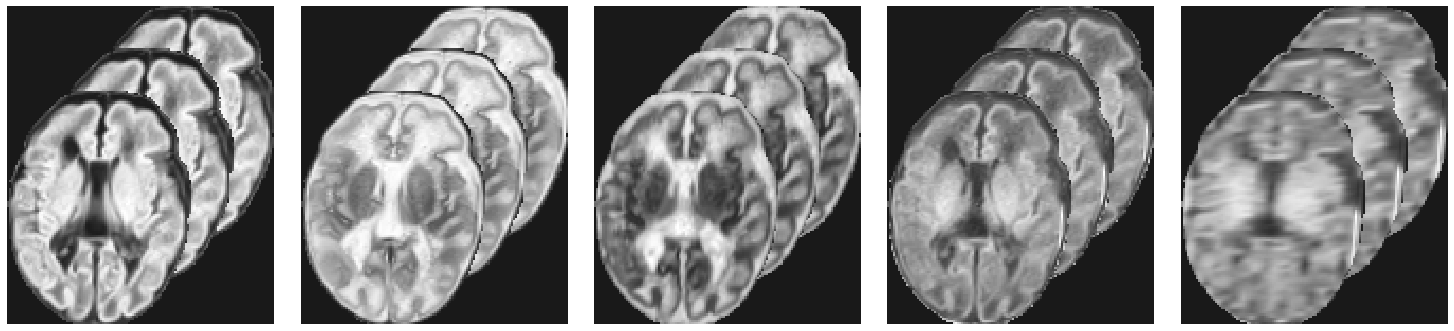

In [4]:
row_index = train_bids.loc[train_bids.Leukomalacia == 1, :].index[32]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow1.pdf')

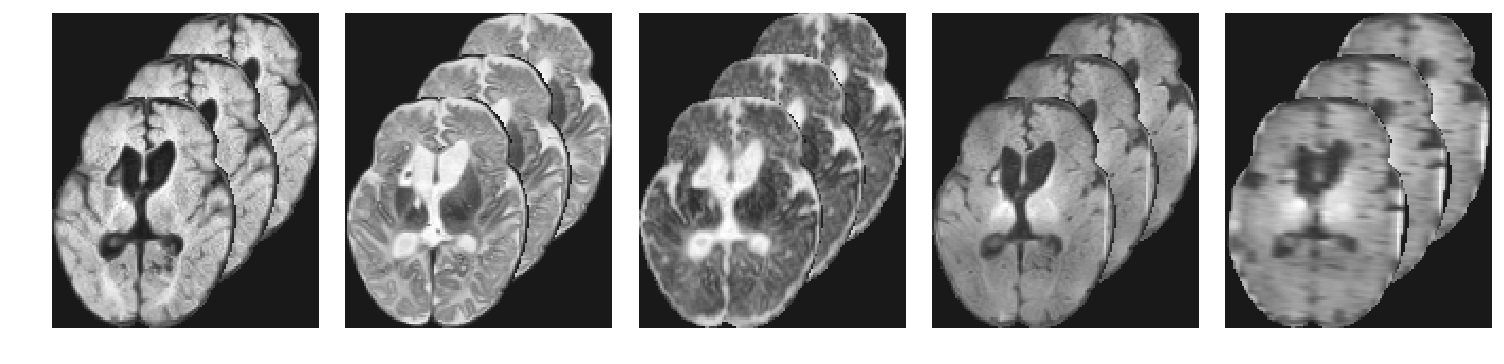

In [679]:
row_index = train_bids.loc[train_bids.Leukomalacia == 1, :].index[80]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow3.pdf')

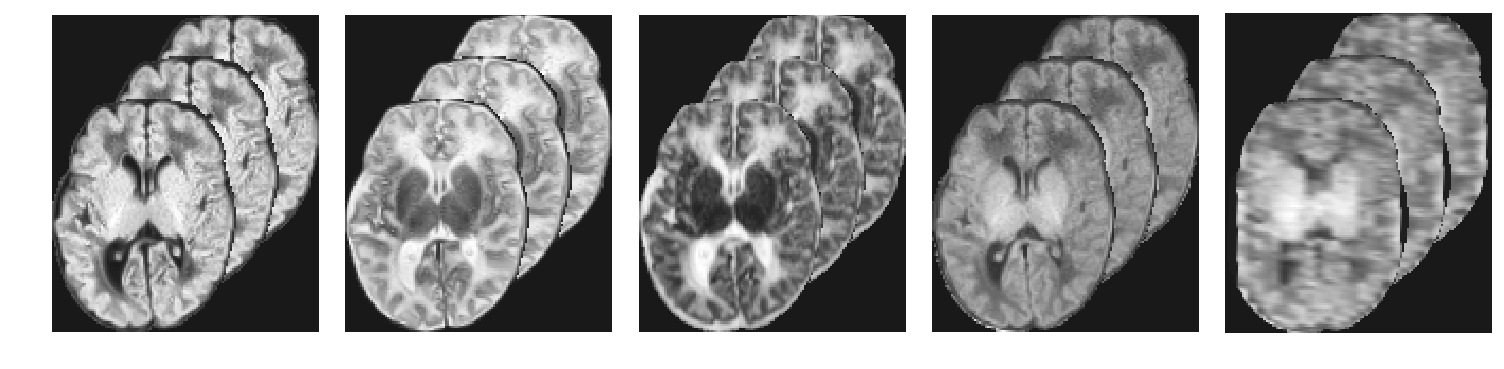

In [677]:
row_index = train_bids.loc[train_bids.Leukomalacia == 1, :].index[52]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow2.pdf')

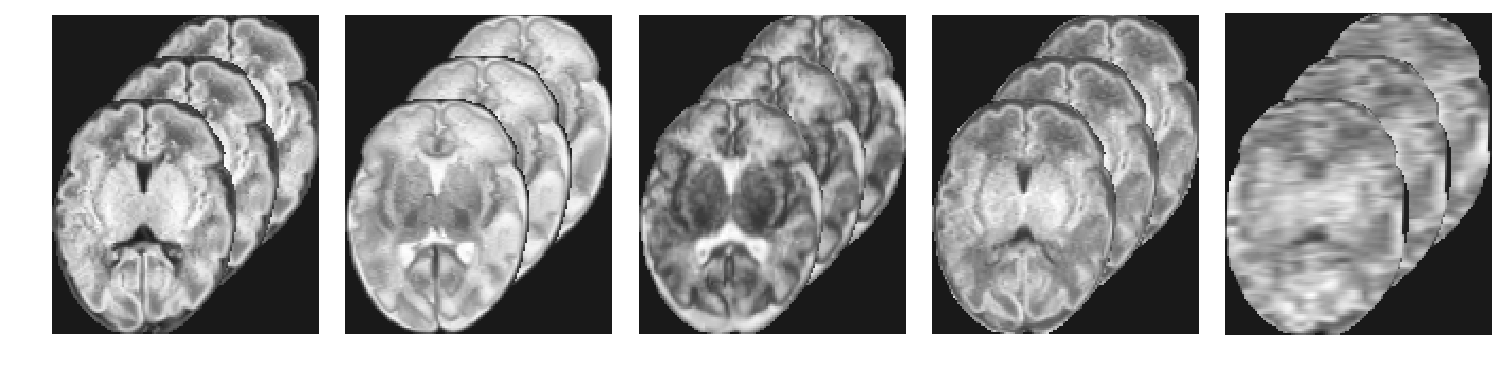

In [681]:
row_index = train_bids.loc[train_bids.Leukomalacia == 1, :].index[55]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow4.pdf')

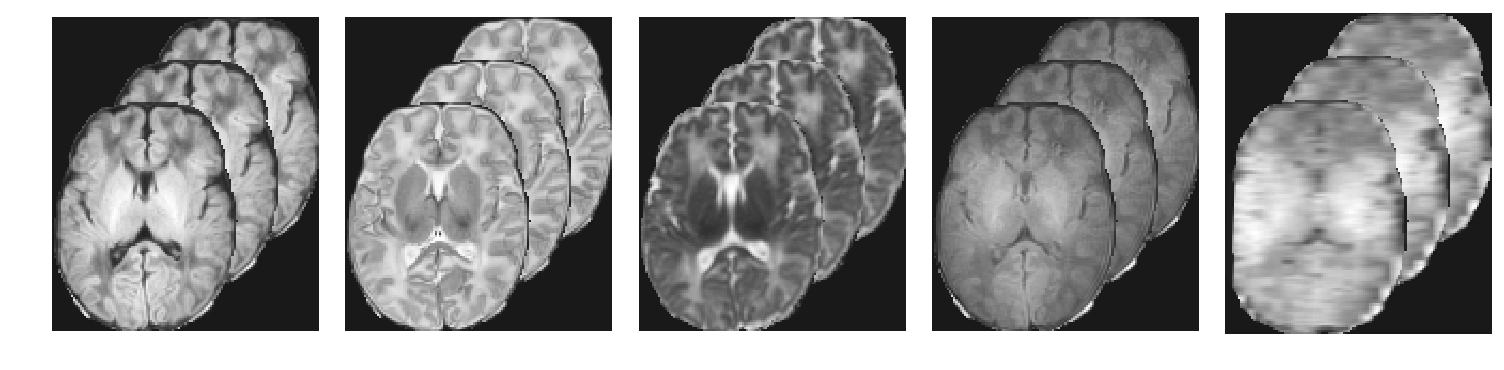

In [683]:
row_index = train_bids.loc[train_bids.Leukomalacia == 0, :].index[55]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow5.pdf')

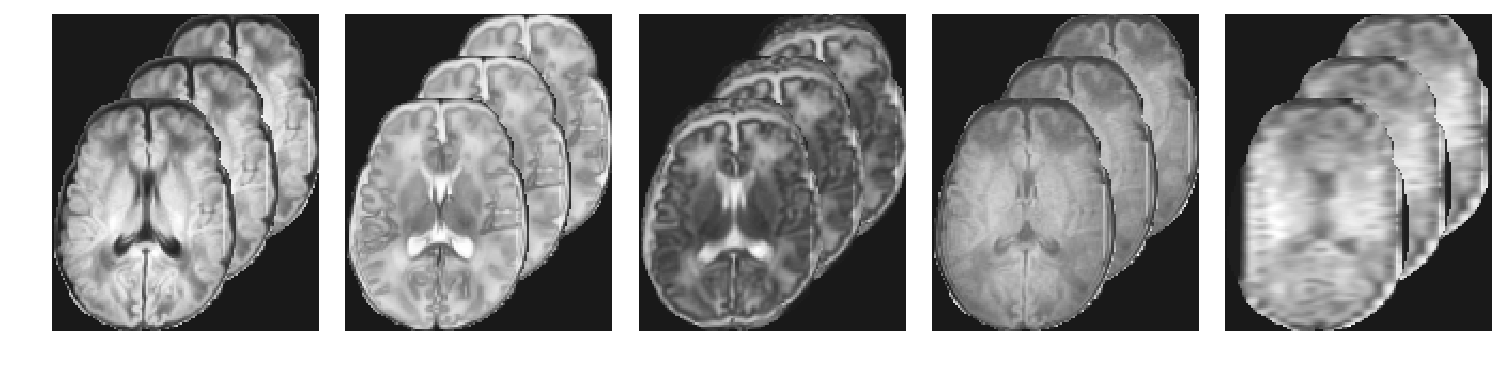

In [684]:
row_index = train_bids.loc[train_bids.Leukomalacia == 0, :].index[60]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow6.pdf')

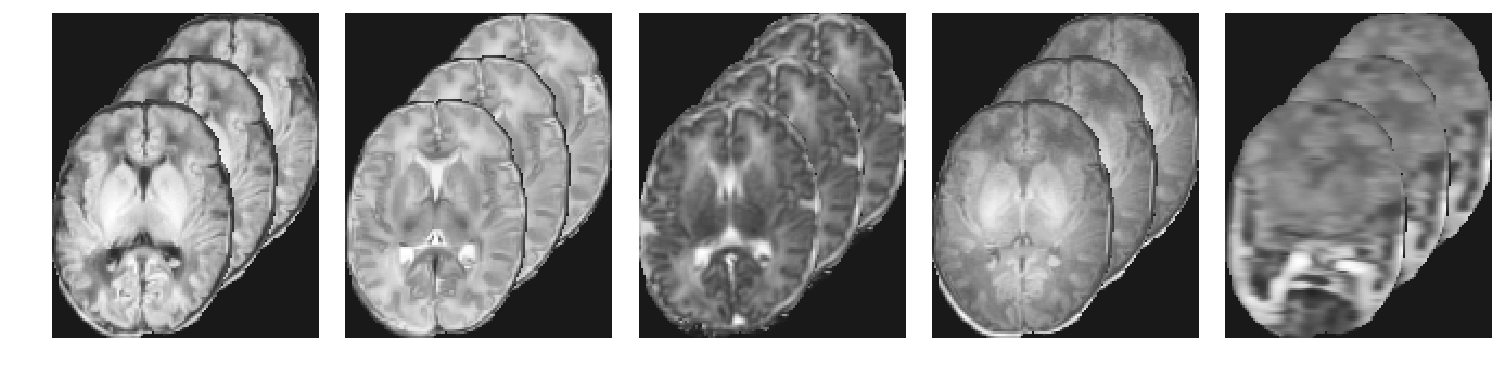

In [685]:
row_index = train_bids.loc[train_bids.Leukomalacia == 0, :].index[100]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([43, 45, 46]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig2_workflow7.pdf')

In [22]:
 test_bids.loc[test_bids.Leukomalacia == 1, :].index[18]

1001

['results/processed/1001_t2f_processed.nii.gz', 'results/processed/1001_t2_processed.nii.gz', 'results/processed/1001_adc_processed.nii.gz', 'results/processed/1001_t1_processed.nii.gz', 'results/processed/1001_t1s_processed.nii.gz']


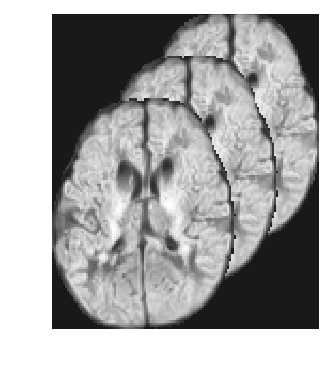

In [25]:
row_index = test_bids.loc[test_bids.Leukomalacia == 1, :].index[18]
all_modalities = [f"results/processed/{row_index}_t2f_processed.nii.gz", # FLAIR
                  f"results/processed/{row_index}_t2_processed.nii.gz",  # T2
                  f"results/processed/{row_index}_adc_processed.nii.gz", # ADC
                  f"results/processed/{row_index}_t1_processed.nii.gz",  # T1
                  f"results/processed/{row_index}_t1s_processed.nii.gz"]  # T1s
print(all_modalities)
!bet {all_modalities[1]} {all_modalities[1]}_mask -m -f 0.4
plt.figure(figsize=[20, 10])
gs = gridspec.GridSpec(1, 5, wspace=0.1, hspace=0.1, 
                       bottom=0, top=1,
                       left=0, right=1)
masks = ants.image_read(f'{all_modalities[1]}_mask.nii.gz')
for i, m in enumerate(all_modalities[:1]):
    t2 = ants.image_read(m)  
    pad = 90
    pad = [(5, pad), (5, pad)]
    demo = np.pad(np.zeros(t2.shape[:2]).T, pad, mode='constant')
    for j, sl in enumerate([50, 51, 52]):
        mask = ants.slice_image(masks, axis=2, idx=sl)
        #mask = ants.iMath_fill_holes(mask, hole_type=2)
        mask = mask.numpy()
        mask = np.rot90(mask)
        mask = np.pad(mask, pad, mode='constant')
        mask = np.roll(mask[:, ::-1], 20*j, axis=0)
        mask = np.roll(mask, -20*j, axis=1).astype(bool)
        img = ants.slice_image(t2, axis=2, idx=sl)
        img = img.numpy()
        img = np.rot90(img)
        img = np.pad(img, pad, mode='constant')            
        img = np.roll(img[:, ::-1], 20*j, axis=0)
        img = np.roll(img, -20*j, axis=1) 
        demo[mask > 0.5] = img[(mask > 0.5)]
    xmin,xmax,ymin,ymax = get_crop(demo)
    plt.subplot(gs[0, i])
    plt.imshow(demo[xmin:xmax, ymin:ymax], 
               cmap=plt.cm.gray,
              # extent=(10, 110, 10, 110),
               alpha=.9)
    plt.axis('off')
plt.savefig('Fig3_a_demo.pdf')

In [8]:
x = torch.zeros(1, 5, 87, 112, 93, dtype=torch.float, requires_grad=False)
model = InceptionAttention3D(5)
out = model(x)

## Visualize network structure

In [6]:
import torchviz

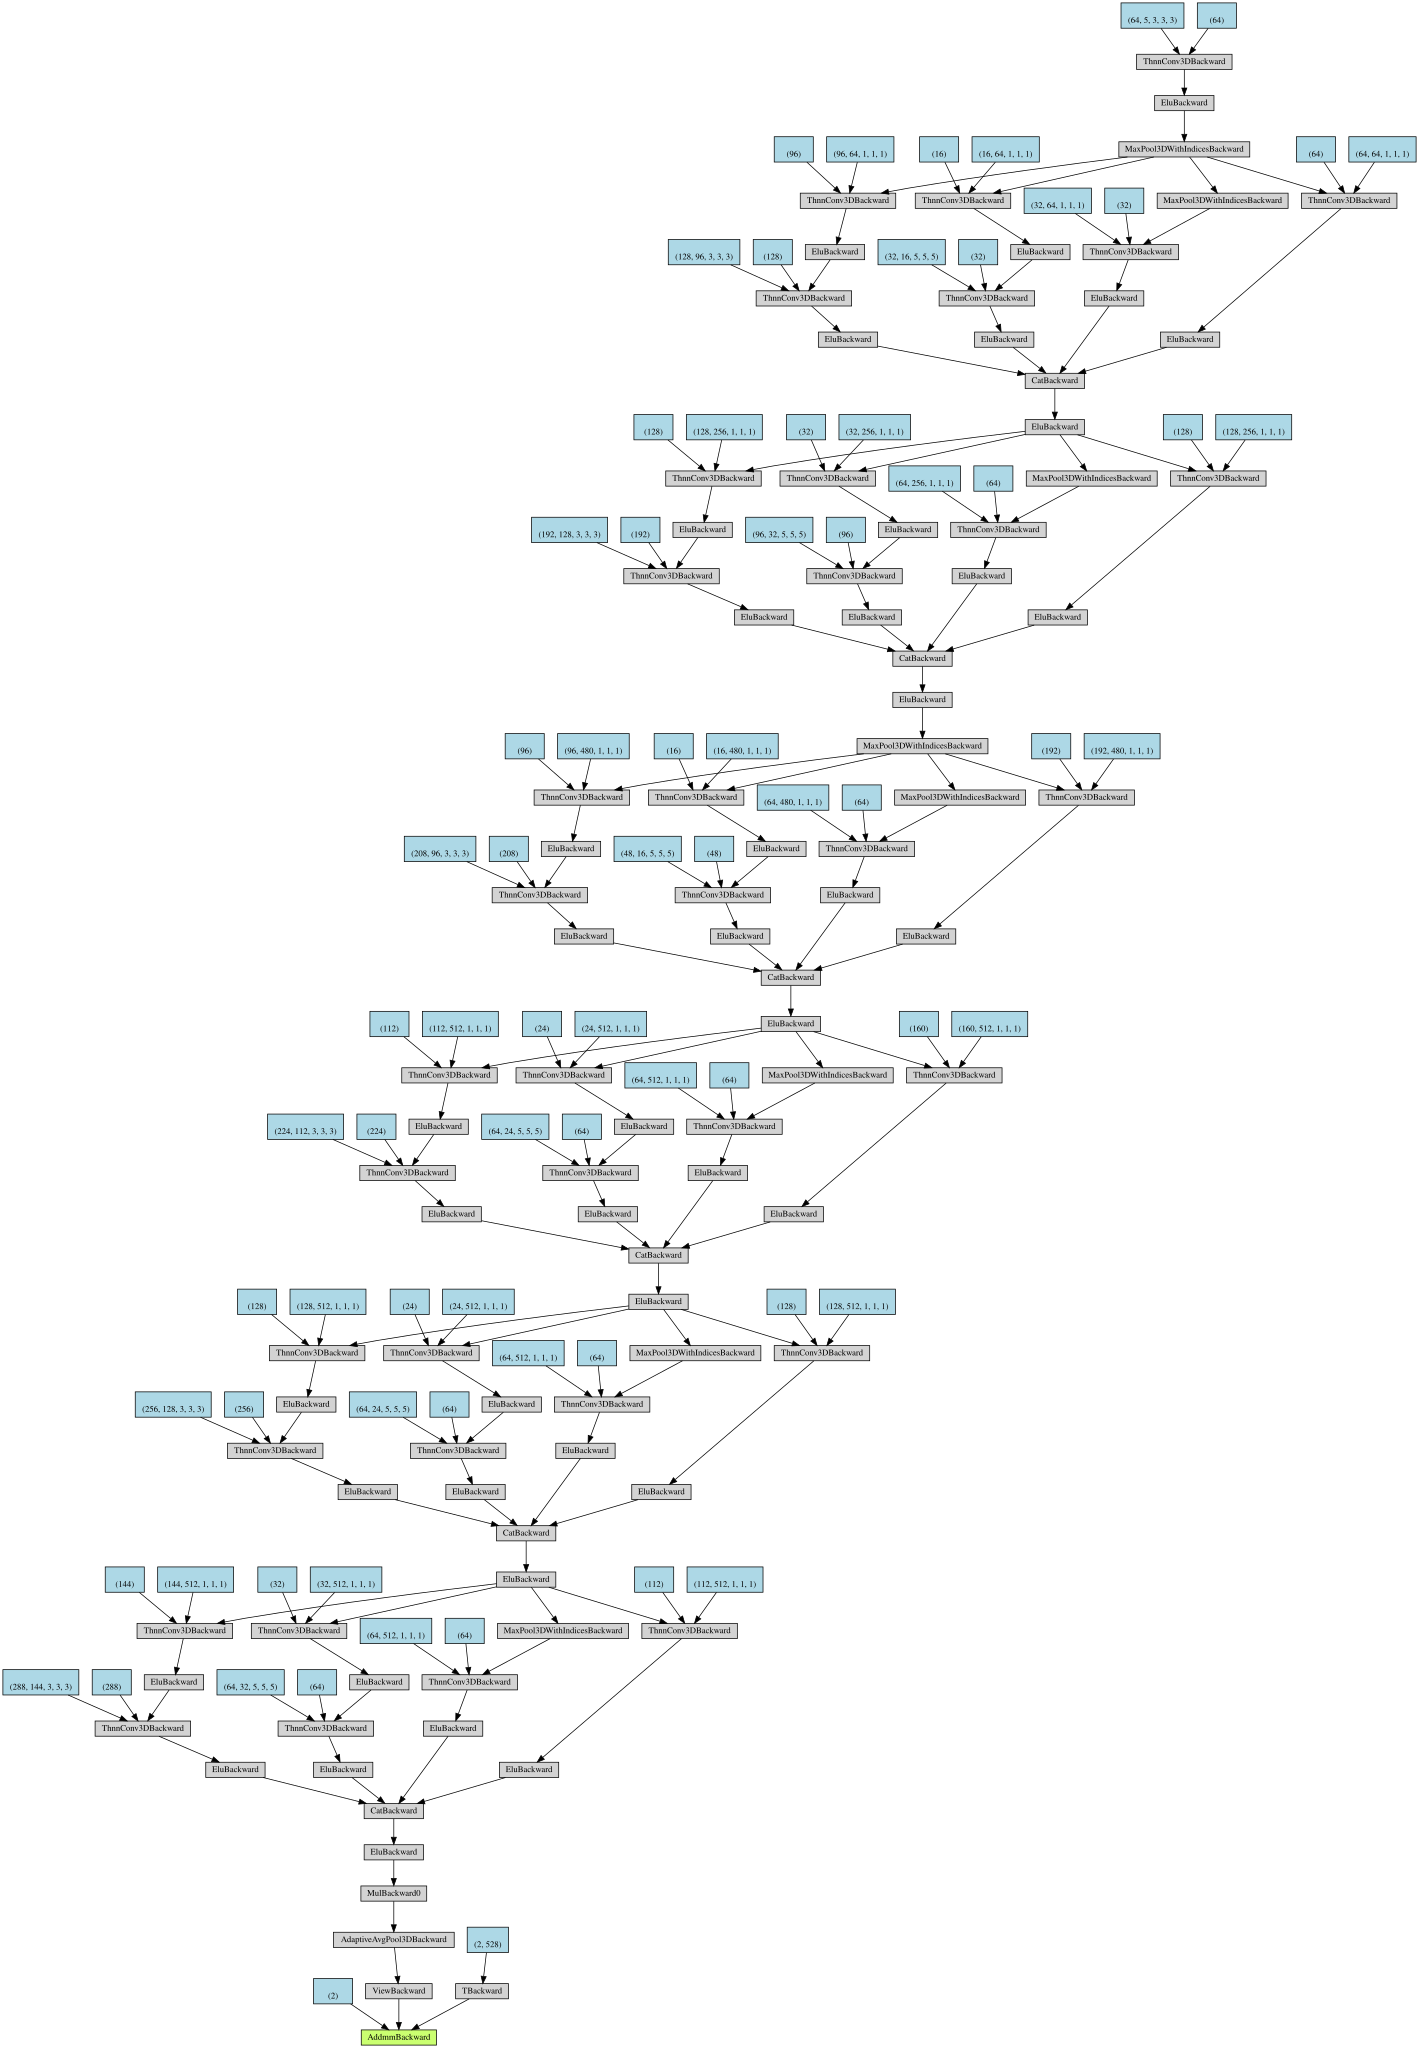

In [9]:
from torchviz import make_dot
make_dot(out)

## visualize all the performance of datasets

In [10]:
def custom_load_checkpoint(path):
    checkpoints= glob(os.path.abspath(path)+'/*')
    epochs, valid_loss, valid_acc = [], [], []
    modal = []
    paths = []
    for epoch_param in checkpoints:
        epoch = int(os.path.basename(epoch_param).split('_')[0].replace('params', ''))        
        vloss = float(os.path.basename(epoch_param).split('_')[6].replace('params', ''))  
        vacc = float(os.path.basename(epoch_param).split('_')[8].replace('params', ''))
        epochs.append(epoch)
        valid_loss.append(vloss)  
        valid_acc.append(vacc)
        modal.append(os.path.basename(os.path.dirname(epoch_param)).split('_')[1].replace('modal', ''))
        paths.append(epoch_param)
    metrics_all = pd.DataFrame(dict(epoch=epochs, validloss=valid_loss, validacc=valid_acc, modal=modal, path=paths))
    metrics_all.sort_values('validloss', inplace=True)
    return metrics_all

In [11]:
metrics_all = []
seeds = [1, 9, 999, 9999, 888]
for seed in seeds:
    for f in glob(f'results/models_Leukomalacia_seed{seed}_pure//Leu*modal*'):
    #for f in glob('results/models_Leukomalacia_gain//Leu*modal*'):
        if f.endswith('valid.csv'):
            df = pd.read_csv(f)
            df.loc[:, 'seed'] = seed
            metrics_all.append(df)
#     metrics = custom_load_checkpoint(f)
#     metrics.sort_values('epoch', inplace=True)
#     metrics_all.append(metrics)

In [28]:
best = []
for m, value in enumerate(metrics_all):
    if len(metrics_all[m].validacc.values)==0:
        continue
    best.append(metrics_all[m].iloc[np.argsort(metrics_all[m].validloss.values)[0],])
best = pd.concat(best, axis=1).transpose()
best.sort_values(['validloss'], inplace=True, ascending=True)
best = best.drop_duplicates(['modal', 'seed'], keep="first")
best_all = best
best_all.loc[:, 'validloss'] = best_all.loc[:, 'validloss']  ## multiply batch size back, since BCELoss already divides batch size

In [29]:
best_all

,Unnamed: 0,epoch,validloss,validacc,modal,path,seed
0,31,65,0.01039,0.82432,0,/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,11,39,0.01061,0.83784,"0,1,2",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,17,53,0.01088,0.83784,"0,1",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,15,55,0.01108,0.86486,0,/cluster/home/qinqian/PVL/results/models_Leuko...,9
0,18,45,0.01111,0.83784,"0,1,3",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,22,58,0.01145,0.81081,"0,3",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,18,50,0.01153,0.86036,"0,2",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,13,33,0.01154,0.86036,"2,3,4",/cluster/home/qinqian/PVL/results/models_Leuko...,9
0,31,89,0.01166,0.79279,1,/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,12,35,0.01179,0.83784,"0,1,2,3,4",/cluster/home/qinqian/PVL/results/models_Leuko...,1


In [19]:
best_all.iloc[0, ].path

'/cluster/home/qinqian/PVL/results/models_Leukomalacia_seed1_pure/Leukomalacia_modal0_class_models_initiallr0.000170_batch32_drop0.5/params65_dataiter_17_currentlr_1.8885111299999998e-05_validloss_0.01039_validacc_0.82432_train_loss_0.00719_train_acc_0.9301.ckpt'

## SCP the models from head1 to results/models_Leukomalacia_head1, and change to local path

## plot ROC and PR curves and barplots about AUCs

In [20]:
def replace_labels(x):
    x = x.replace('2', 'Axial ADC')    
    x = x.replace('1', 'Axial T2w')        
    x = x.replace('0', 'Axial T2 FLAIR')
    x = x.replace('3', 'Axial T1w')
    x = x.replace('4', 'T1w Saggital')
    x = x.replace(',', '+')
    return x
 
#too long labels ugly
#best.modal = best.modal.map(replace_labels)
labels = "0:Axial T2 FLAIR  1:Axial T2w  2:Axial ADC 3:Axial T1w 4:T1w Saggital"

<Figure size 1584x720 with 0 Axes>

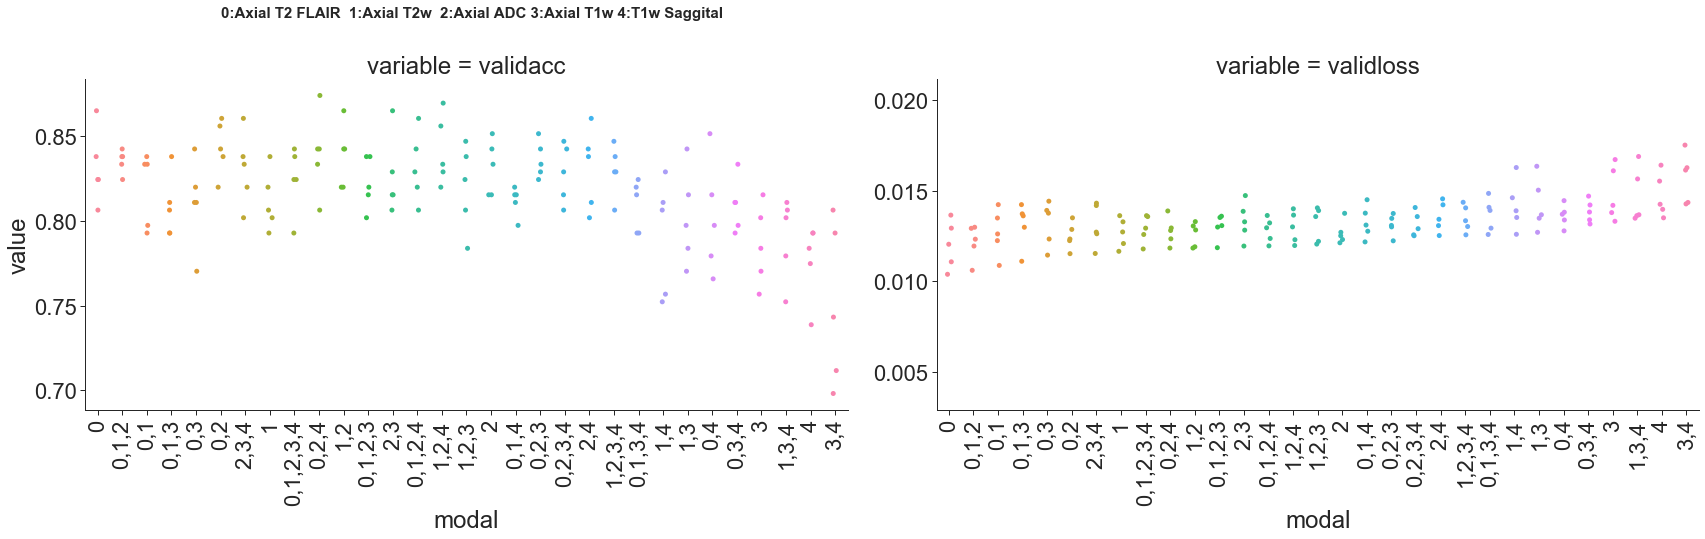

In [30]:
best_all.sort_values('validloss', inplace=True, ascending=True)
vis_valid_data = best_all.melt(id_vars=['modal', 'seed'], 
                         value_vars=['validacc', 'validloss'])
vis_valid_data.head()
plt.figure(figsize=(22, 10))
g = sns.catplot(x="modal", y="value", aspect=2, col="variable",
            hue="modal", sharey=False, data=vis_valid_data,
            height=6)
g.axes[-1][0].text(5, 0.92,
                   labels, 
                   style='normal',fontweight='bold',fontsize=15,
                   bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
(g.set_xticklabels(rotation=90).despine())
for i in g.axes:
    for j in i:
        j.margins = [5,5,5,5]
# barplot below
# plt.subplot(2, 1, 1)
# ax = sns.barplot(x="modal", y="validacc", data=best_all,
#                  dodge=False, color='gray')
# sns.despine()
# plt.tick_params(axis='x', rotation=90, width=1)
# plt.ylim([0.5, 1])
# ax.text(32, 0.7, labels, style='normal',fontweight='bold',fontsize=12,
#         bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
# best_all.sort_values('validloss', inplace=True, ascending=True)
# plt.subplot(2, 1, 2)
# ax = sns.barplot(x="modal", y="validloss",
#                  data=best_all, dodge=False, color='gray')
# ax.text(32, 0.015, labels, style='normal',fontweight='bold',fontsize=15,
#          bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
# sns.despine()
# plt.tick_params(axis='x', rotation=90, width=1)
# plt.ylim([0, 0.04])
# plt.tight_layout()
g.savefig('results/FigS2.pdf', height=12) # weird axis labels

In [31]:
best_log = 'results/Leukomalacia_modal0_class_models_initiallr0.00017_batch32_drop0.5_seed1.logs'

In [32]:
train_losses = []
train_accs = []
valid_losses = []
valid_accs = []
n = 0
with open(best_log) as log:
    for line in log:
        if line.startswith('[') and 'loss' in line and 'train' in line:
            elems = line.strip().split(':')
            print(line)
            train_loss = elems[1].replace(', acc', '')
            train_acc  = elems[2].replace(', lr', '')
            train_losses.append(float(train_loss))
            train_accs.append(float(train_acc))
        if line.startswith('[') and 'loss' in line and 'valid' in line:
            elems = line.strip().split(':')
            print(line)
            valid_loss = elems[1].replace(', acc', '')
            valid_acc  = elems[2].replace(', lr', '')
            valid_losses.append(float(valid_loss))
            valid_accs.append(float(valid_acc))            

[1,    10] train loss: 0.0831, acc: 0.5750, lr:0.000170000

[1,    17] valid loss: 0.0220, acc: 0.6667, lr:0.000170000

[2,    10] train loss: 0.0215, acc: 0.6937, lr:0.000170000

[2,    17] valid loss: 0.0263, acc: 0.6667, lr:0.000170000

[3,    10] train loss: 0.0218, acc: 0.6125, lr:0.000170000

[3,    17] valid loss: 0.0192, acc: 0.6802, lr:0.000170000

[4,    10] train loss: 0.0204, acc: 0.6531, lr:0.000170000

[4,    17] valid loss: 0.0195, acc: 0.6667, lr:0.000170000

[5,    10] train loss: 0.0189, acc: 0.6844, lr:0.000170000

[5,    17] valid loss: 0.0197, acc: 0.6892, lr:0.000170000

[6,    10] train loss: 0.0188, acc: 0.6969, lr:0.000170000

[6,    17] valid loss: 0.0234, acc: 0.6667, lr:0.000170000

[7,    10] train loss: 0.0203, acc: 0.6625, lr:0.000170000

[7,    17] valid loss: 0.0195, acc: 0.6667, lr:0.000170000

[8,    10] train loss: 0.0181, acc: 0.6875, lr:0.000170000

[8,    17] valid loss: 0.0182, acc: 0.6937, lr:0.000170000

[9,    10] train loss: 0.0179, acc: 0.68

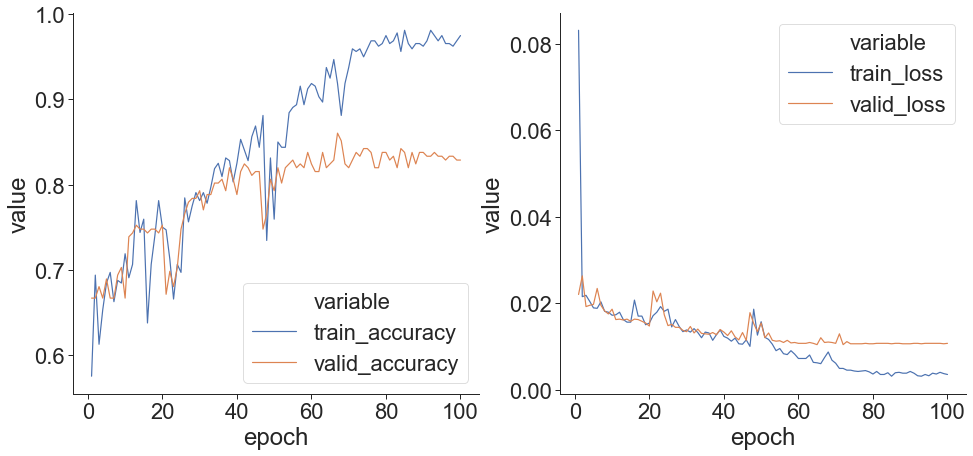

In [34]:
result = pd.DataFrame({'epoch': np.arange(1, 101),
                       'train_accuracy':train_accs, 'train_loss': np.array(train_losses),
                       'valid_accuracy': valid_accs, 'valid_loss': np.array(valid_losses)})

plt.figure(figsize=(16, 7))
plt.subplot(1,2,1)
sns.lineplot(x='epoch', y='value', hue='variable',
             data=result.melt(id_vars=['epoch'], value_vars=['train_accuracy', 'valid_accuracy']))
sns.despine()
plt.subplot(1,2,2)
sns.lineplot(x='epoch', y='value', hue='variable',
             data=result.melt(id_vars=['epoch'], value_vars=['train_loss', 'valid_loss']))
sns.despine()
plt.savefig("results/FigS2_2.pdf")

results/models_Leukomalacia_seed1_pure/Leukomalacia_modal0_class_models_initiallr0.000170_batch32_drop0.5_test.csv
results/models_Leukomalacia_seed1_pure/Leukomalacia_modal0,1,2_class_models_initiallr0.000170_batch32_drop0.5_test.csv
results/models_Leukomalacia_seed1_pure/Leukomalacia_modal0,1_class_models_initiallr0.000170_batch32_drop0.5_test.csv


/home/qinqian/.local/lib/python3.6/site-packages/scipy-1.0.1-py3.6-linux-x86_64.egg/scipy/stats/stats.py:1706: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.



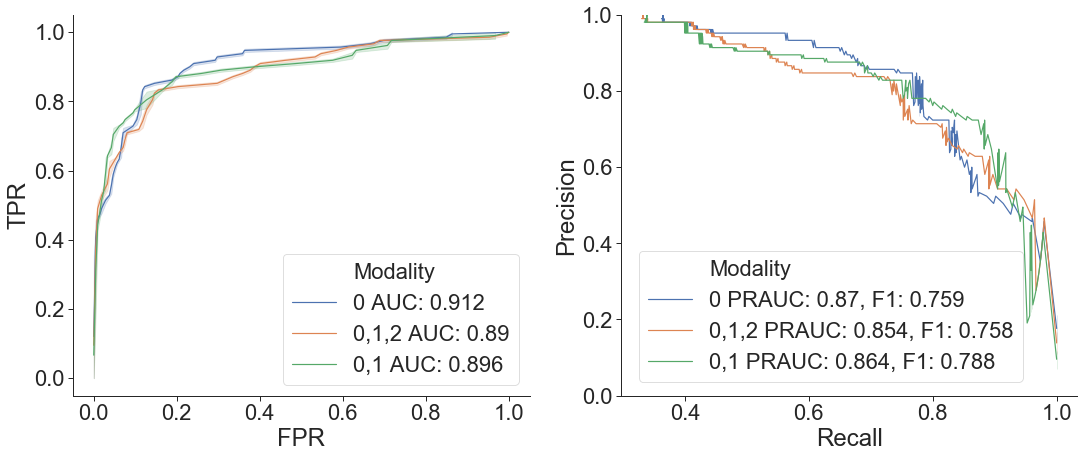

In [316]:
results_roc = []
results_pr  = []
test_scores = {}
best_all_seed1 = best_all.loc[best_all.seed == 1, :]
all_metrics = []
for m, p in zip(best_all_seed1.modal[:3], best_all_seed1.path[:3]):
    test_csv = os.path.dirname(p).replace('/cluster/home/qinqian/PVL/', '') + "_test.csv"
    print(test_csv)
    if os.path.exists(test_csv):
        df = pd.read_csv(test_csv)
        for sc in scoring:
            if sc in ['AUC', 'PRAUC']:
                test_scores[sc] = round(scoring[sc](df.loc[:, "labels"], df.loc[:, 'outputs']), 3)
            else:
                test_scores[sc] = round(scoring[sc](df.loc[:, "labels"], df.loc[:, 'predict']), 3)
        fpr, tpr, _ = roc_curve(df.loc[:, "labels"], df.loc[:, 'outputs'])
        pr, recall, _ = precision_recall_curve(df.loc[:, "labels"], df.loc[:, 'outputs'])
        
        results_roc.append(pd.DataFrame(dict(fpr=fpr, tpr=tpr, 
                                             modality=[str(m) + " AUC: %s" % test_scores['AUC']] * len(tpr))))
        results_pr.append(pd.DataFrame(dict(pr=pr, recall=recall, 
                                            modality=[str(m) + " PRAUC: %s, F1: %s" % (test_scores['PRAUC'], test_scores['f1'])] * len(pr))))
        all_metrics.append(test_scores)

results_roc = pd.concat(results_roc, axis=0)
results_pr =  pd.concat(results_pr, axis=0)
results_roc.columns = ['FPR', 'TPR', 'Modality']
results_pr.columns = ['Recall', 'Precision', 'Modality']
plt.figure(figsize=(18, 7))
plt.subplot(1, 2, 1)
sns.lineplot(x="FPR", y="TPR", hue="Modality", data=results_roc, 
             dashes=False, legend="brief")
plt.subplot(1, 2, 2)
sns.lineplot(x="Recall", y="Precision", hue="Modality", data=results_pr,
             dashes=False, legend="full")
plt.ylim([0, 1.0])
plt.legend(bbox_to_anchor=(0.88, 0.38), loc=0, borderaxespad=0.)
#plt.tight_layout()
sns.despine()
plt.savefig('results/Fig2.pdf')

In [317]:
best_all_seed1 = best_all.loc[best_all.seed == 1, :]
best_all_seed1.head()

,Unnamed: 0,epoch,validloss,validacc,modal,path,seed
0,31,65,0.01039,0.82432,0,/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,11,39,0.01061,0.83784,"0,1,2",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,17,53,0.01088,0.83784,"0,1",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,18,45,0.01111,0.83784,"0,1,3",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,22,58,0.01145,0.81081,"0,3",/cluster/home/qinqian/PVL/results/models_Leuko...,1


In [272]:
all_metrics = []
n_bootstraps = 1000
rng_seed = 42  # control reproducibility
bootstrapped_scores = []
rng = np.random.RandomState(rng_seed)
modals = []
bootstraps = []
## https://stackoverflow.com/questions/19124239/scikit-learn-roc-curve-with-confidence-intervals
for m, p in zip(best_all_seed1.modal, best_all_seed1.path):
    test_csv = os.path.dirname(p).replace('/cluster/home/qinqian/PVL/', '') + "_test.csv"
    if os.path.exists(test_csv):
        df = pd.read_csv(test_csv)
        for i in range(n_bootstraps):
            test_scores = {}
            # bootstrap by sampling with replacement on the prediction indices
            indices = rng.randint(0, df.shape[0], df.shape[0])
            if len(np.unique(df.iloc[indices, :].loc[:, 'labels'])) < 2:
                # We need at least one positive and one negative sample for ROC AUC
                # to be defined: reject the sample
                continue
            for sc in scoring:                
                if sc in ['AUC', 'PRAUC']:
                    test_scores[sc] = round(scoring[sc](df.iloc[indices, :].loc[:, "labels"],
                                                        df.iloc[indices, :].loc[:, 'outputs']), 4)
                else:
                    test_scores[sc] = round(scoring[sc](df.iloc[indices, :].loc[:, "labels"], 
                                                        df.iloc[indices, :].loc[:, 'predict']), 4)
            bootstrapped_scores.append(test_scores)
            bootstraps.append(i)
            modals.append(m)

In [276]:
metrics = pd.DataFrame(bootstrapped_scores)
metrics.loc[:, 'modal'] = modals
metrics.loc[:, 'bootstrap'] = bootstraps
metrics.head()

,AUC,Accuracy,FNR,FPR,PRAUC,f1,precision,recall,specificity,modal,bootstrap
0,0.9378,0.8770,0.0837,0.0877,0.8768,0.7821,0.7778,0.7865,0.9123,0,0
1,0.8829,0.8233,0.1379,0.1379,0.8519,0.7544,0.7544,0.7544,0.8621,0,1
2,0.9221,0.8707,0.1156,0.0701,0.8819,0.7897,0.8370,0.7476,0.9299,0,2
3,0.9313,0.8580,0.1441,0.0640,0.9003,0.7847,0.8632,0.7193,0.9360,0,3
4,0.9190,0.8423,0.1422,0.0922,0.8795,0.7619,0.8081,0.7207,0.9078,0,4


In [284]:
metrics.to_csv('bootstrap1000_classification_seed1_pvl.csv')

In [287]:
metrics_melt = metrics.melt(id_vars=['modal', 'bootstrap'])
metrics_melt.head(3)

,modal,bootstrap,variable,value
0,0,0,AUC,0.9378
1,0,1,AUC,0.8829
2,0,2,AUC,0.9221


/home/qinqian/.local/lib/python3.6/site-packages/scipy-1.0.1-py3.6-linux-x86_64.egg/scipy/stats/stats.py:1706: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.



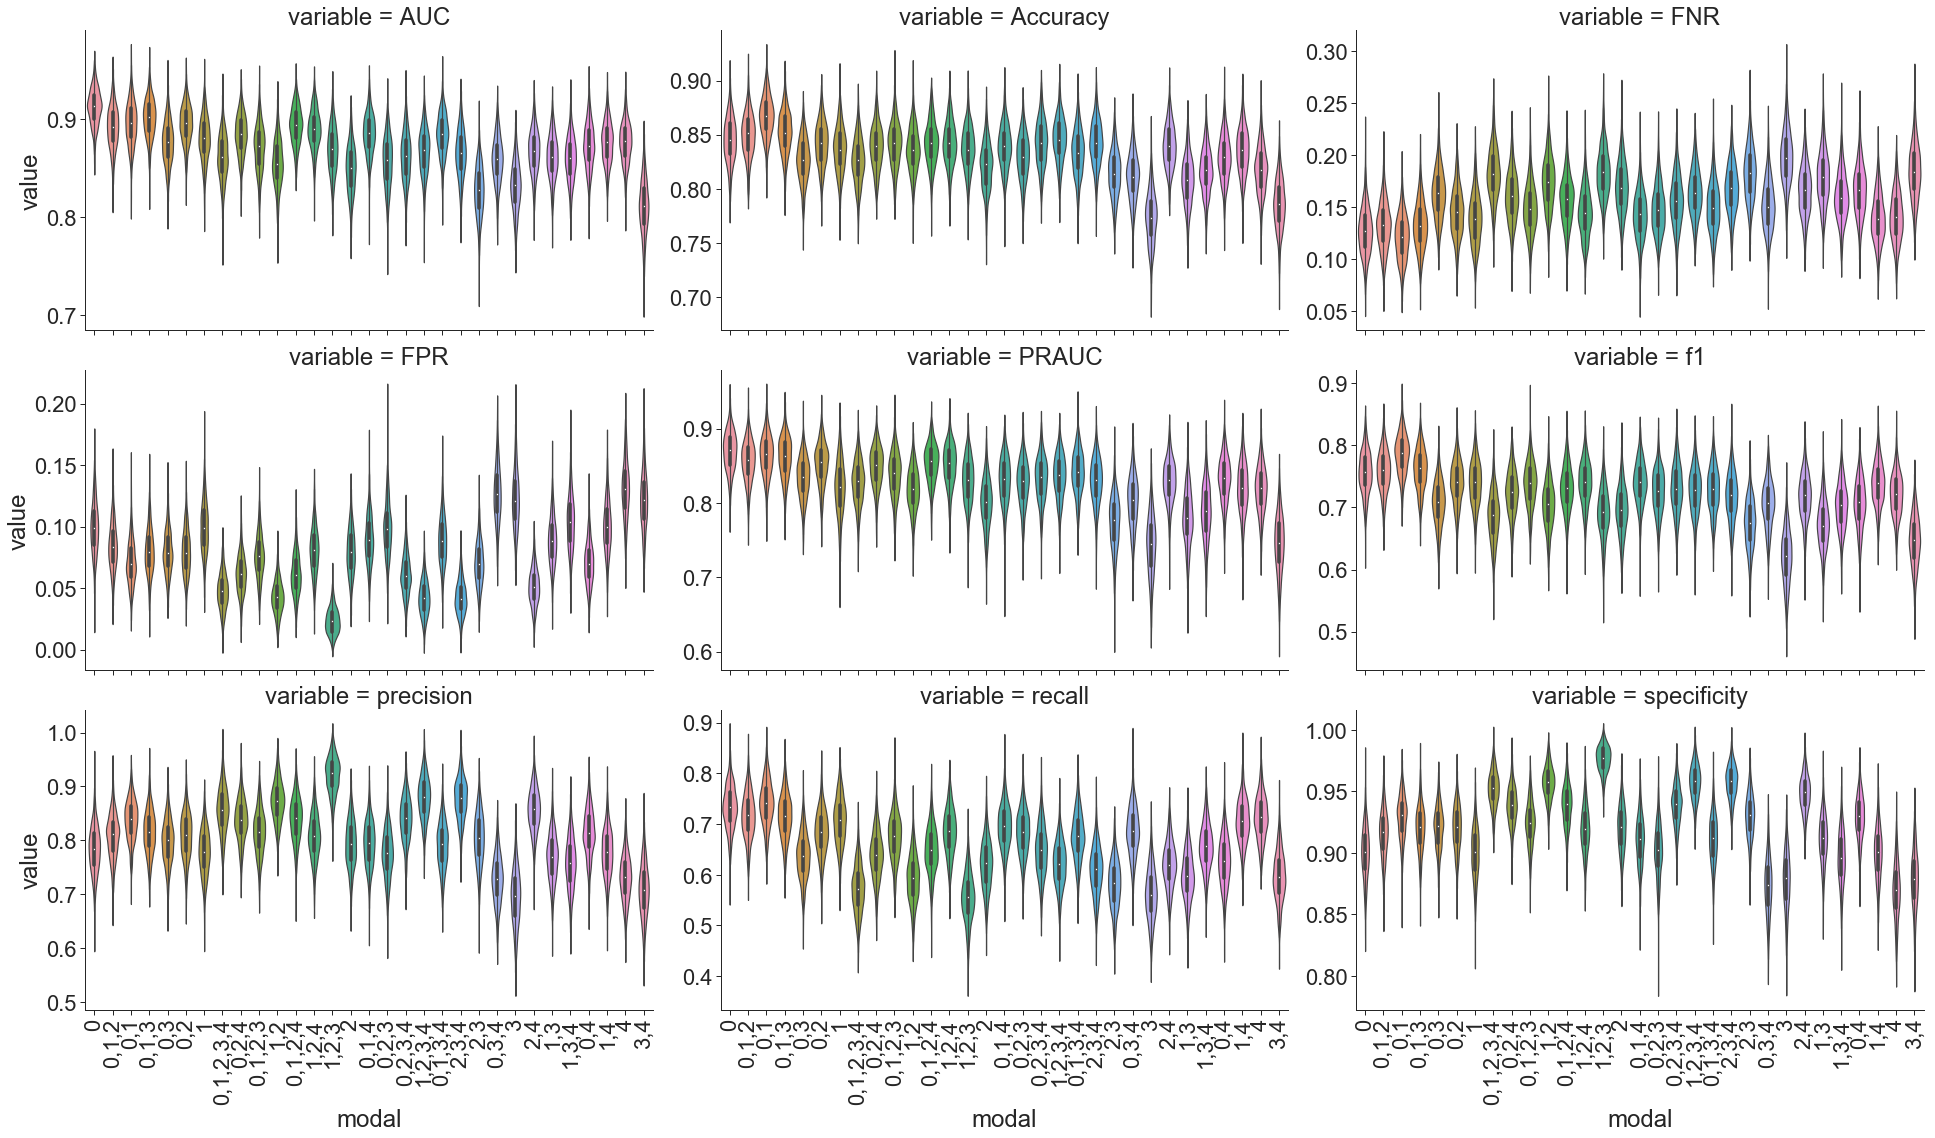

In [308]:
# gs = gridspec.GridSpec(2, 2, wspace=0.18, hspace=0.5, bottom=0.5, top=0.94, left=0.1, right=0.75)
# def plot_metrics(x, performances):
#     performances = performances.sort_values(x, ascending=False)    
#     ax = sns.barplot(x='modal', y=x, data=performances, 
#                      dodge=False, color="lightblue", saturation=0.9)
#     sns.despine()
#     plt.tick_params(axis='x', rotation=90, width=1)
#     ax.margins = [5,5,5,5]
#     plt.ylim([0.5, 1])
#     plt.xlabel("")
#     if x == 'f1':
#         plt.ylabel('F1')
#     return ax
# plt.figure(figsize=(25, 16))
# plt.subplot(gs[0, 0])
# plot_metrics('Accuracy', metrics)
# plt.subplot(gs[0, 1])
# plot_metrics('AUC', metrics)
# plt.subplot(gs[1, 0])
# plot_metrics('f1', metrics)
# ax = plt.subplot(gs[1, 1])
# ax = plot_metrics('PRAUC', metrics)
# ax.text(32, 0.015, labels, style='normal',fontweight='bold',fontsize=25,
#         bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
# plt.savefig("results/Fig2.pdf")
g = sns.catplot(x='modal', y='value', col='variable', sharey=False,
                aspect=1.8,
                col_wrap=3, data=metrics_melt, kind='violin')
g.set_xticklabels(rotation=90)
g.savefig('results/Fig2_2.pdf')

/home/qinqian/.local/lib/python3.6/site-packages/scipy-1.0.1-py3.6-linux-x86_64.egg/scipy/stats/stats.py:1706: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.



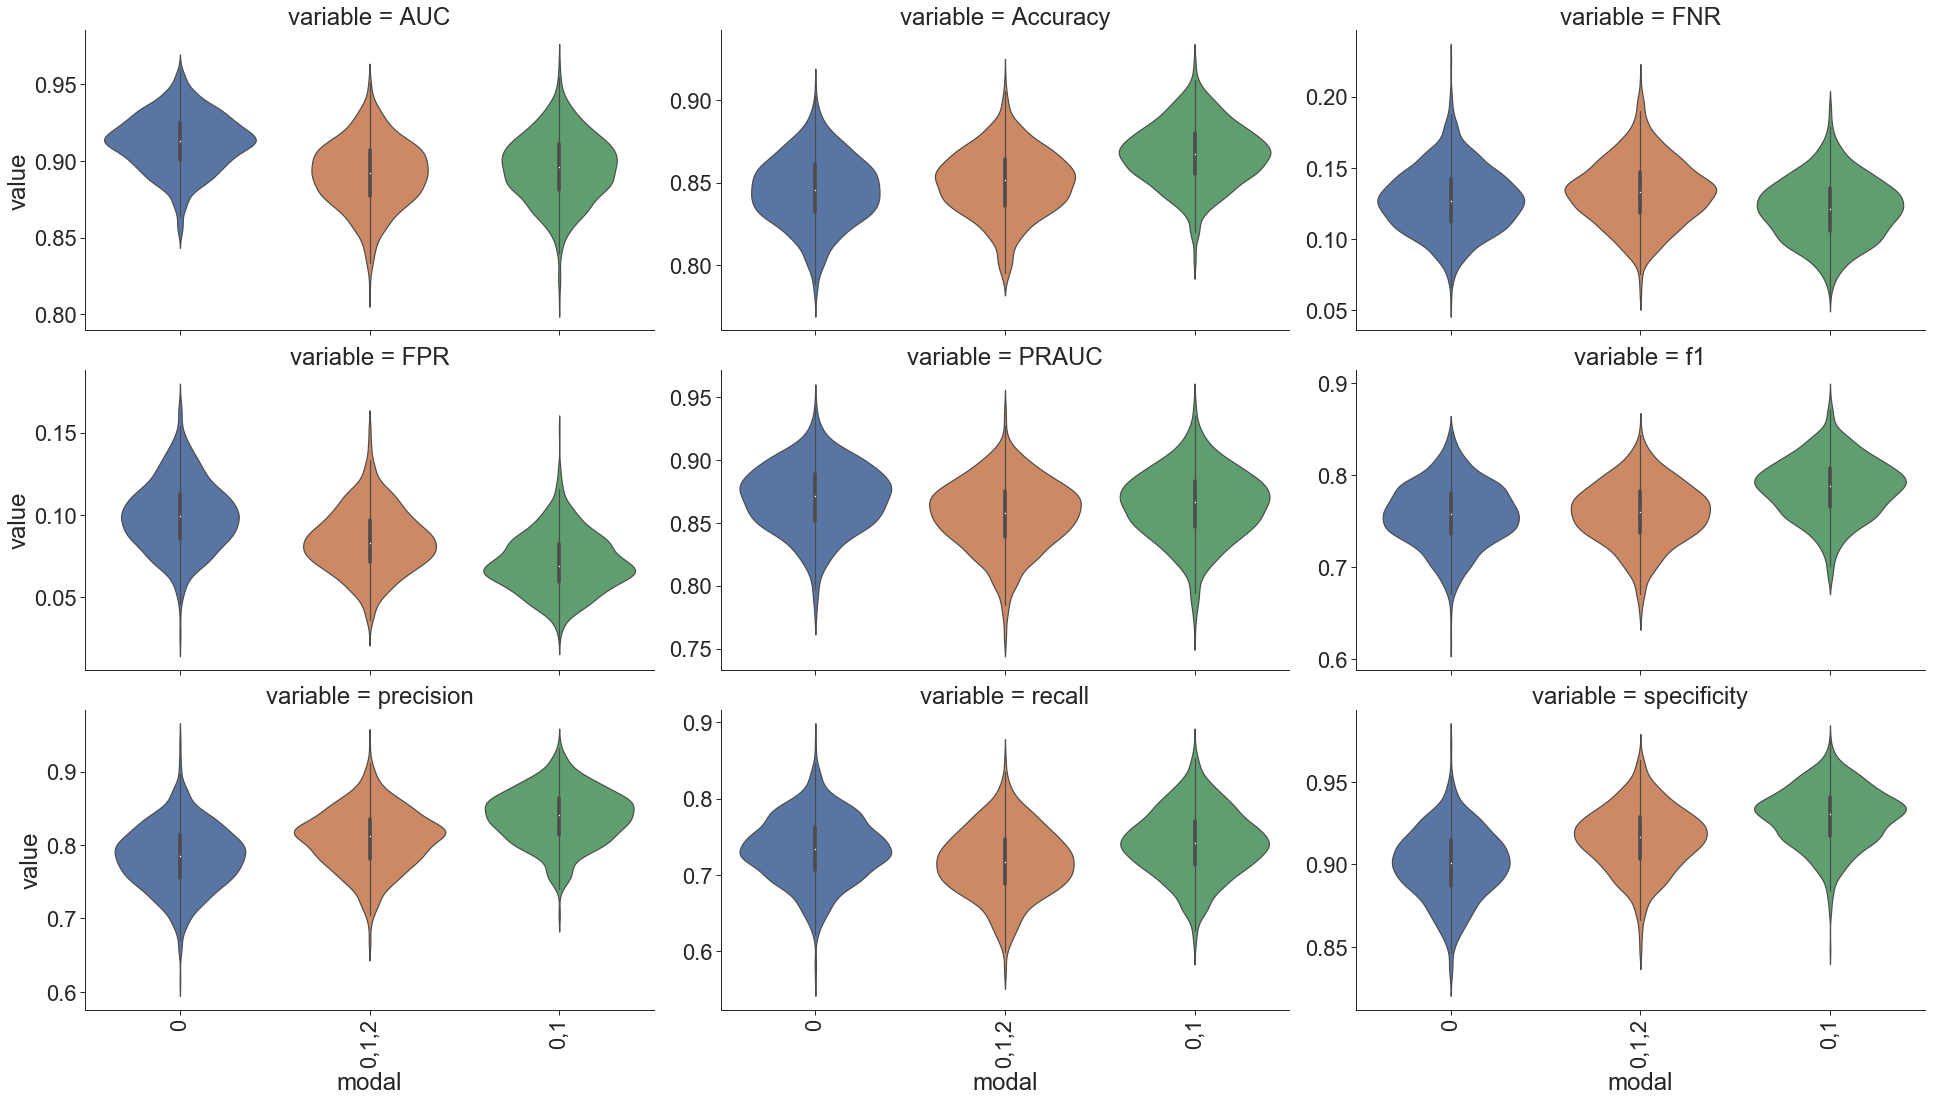

In [324]:
g = sns.catplot(x='modal', y='value', col='variable', sharey=False,
                aspect=1.8,
                col_wrap=3, data=metrics_melt[metrics_melt.modal.isin([0, '0,1,2', '0,1'])],
                kind='violin')
g.set_xticklabels(rotation=90)
g.savefig('results/Fig2_3.pdf')

In [333]:
metrics.head()

,AUC,Accuracy,FNR,FPR,PRAUC,f1,precision,recall,specificity,modal,bootstrap
0,0.9378,0.8770,0.0837,0.0877,0.8768,0.7821,0.7778,0.7865,0.9123,0,0
1,0.8829,0.8233,0.1379,0.1379,0.8519,0.7544,0.7544,0.7544,0.8621,0,1
2,0.9221,0.8707,0.1156,0.0701,0.8819,0.7897,0.8370,0.7476,0.9299,0,2
3,0.9313,0.8580,0.1441,0.0640,0.9003,0.7847,0.8632,0.7193,0.9360,0,3
4,0.9190,0.8423,0.1422,0.0922,0.8795,0.7619,0.8081,0.7207,0.9078,0,4


In [686]:
metrics.groupby(['modal']).mean()

,AUC,Accuracy,FNR,FPR,PRAUC,f1,precision,recall,specificity,bootstrap
modal,,,,,,,,,,
0,0.912209,0.845144,0.127433,0.099792,0.869704,0.756931,0.783753,0.733569,0.900208,499.5
1,0.879762,0.836137,0.138866,0.099851,0.819790,0.739485,0.777721,0.706646,0.900149,499.5
2,0.848617,0.820637,0.169908,0.080000,0.799753,0.695234,0.793742,0.620271,0.920000,499.5
3,0.831546,0.772999,0.198194,0.122555,0.742406,0.619967,0.694481,0.561932,0.877445,499.5
4,0.876198,0.817533,0.140780,0.130830,0.818312,0.721192,0.730743,0.713694,0.869170,499.5
"0,1",0.895486,0.867094,0.121005,0.070852,0.864071,0.786317,0.838492,0.741793,0.929148,499.5
"0,1,2",0.891456,0.849775,0.132748,0.084392,0.856244,0.758610,0.807886,0.716750,0.915608,499.5
"0,1,2,3",0.870397,0.841334,0.148750,0.076092,0.837933,0.737511,0.814958,0.675095,0.923907,499.5
"0,1,2,3,4",0.861411,0.825893,0.182848,0.047791,0.827582,0.685042,0.856448,0.572461,0.952209,499.5


In [340]:
metrics_group = metrics.groupby(['modal'])

In [357]:
metrics_group.agg(lambda x:sorted(x)[int(0.05*len(x))])

,AUC,Accuracy,FNR,FPR,PRAUC,f1,precision,recall,specificity,bootstrap
modal,,,,,,,,,,
0,0.8818,0.8107,0.0909,0.0682,0.8249,0.6996,0.7129,0.6609,0.8638,50
1,0.8416,0.8013,0.1005,0.0680,0.7525,0.6809,0.7089,0.6311,0.8654,50
2,0.8071,0.7823,0.1304,0.0502,0.7421,0.6279,0.7216,0.5385,0.8894,50
3,0.7897,0.7350,0.1561,0.0860,0.6719,0.5465,0.6067,0.4793,0.8363,50
4,0.8420,0.7823,0.1038,0.0922,0.7644,0.6637,0.6606,0.6404,0.8295,50
"0,1",0.8597,0.8360,0.0868,0.0439,0.8178,0.7330,0.7717,0.6667,0.8990,50
"0,1,2",0.8555,0.8170,0.0952,0.0538,0.8075,0.7000,0.7391,0.6417,0.8843,50
"0,1,2,3",0.8307,0.8044,0.1116,0.0478,0.7850,0.6738,0.7471,0.5979,0.8942,50
"0,1,2,3,4",0.8237,0.7918,0.1411,0.0243,0.7777,0.6180,0.7826,0.4948,0.9272,50


In [356]:
metrics_group.agg(lambda x:sorted(x)[int(0.95*len(x))])

,AUC,Accuracy,FNR,FPR,PRAUC,f1,precision,recall,specificity,bootstrap
modal,,,,,,,,,,
0,0.9418,0.8770,0.1643,0.1364,0.9097,0.8122,0.8506,0.8000,0.9318,950
1,0.9169,0.8707,0.1805,0.1350,0.8783,0.7981,0.8444,0.7802,0.9324,950
2,0.8872,0.8549,0.2112,0.1106,0.8506,0.7594,0.8652,0.7000,0.9498,950
3,0.8721,0.8139,0.2435,0.1649,0.8069,0.6878,0.7791,0.6449,0.9140,950
4,0.9099,0.8517,0.1810,0.1705,0.8684,0.7778,0.8000,0.7850,0.9082,950
"0,1",0.9305,0.8991,0.1565,0.1010,0.9067,0.8372,0.8969,0.8137,0.9561,950
"0,1,2",0.9266,0.8801,0.1708,0.1165,0.8981,0.8119,0.8713,0.7876,0.9463,950
"0,1,2,3",0.9076,0.8738,0.1881,0.1058,0.8832,0.7923,0.8831,0.7459,0.9524,950
"0,1,2,3,4",0.8972,0.8612,0.2236,0.0728,0.8744,0.7463,0.9254,0.6495,0.9757,950


In [386]:
output_1 = metrics_group.describe(percentiles=[0.05, 0.95], include=np.number)
with pd.option_context('precision', 2):
    display(output_1)
output_1.to_csv('Table2_confinterval.txt', sep='\t')

AUC                                           Accuracy        \
            count  mean   std   min    5%   50%   95%   max    count  mean   
modal                                                                        
0          1000.0  0.91  0.02  0.85  0.88  0.91  0.94  0.96   1000.0  0.85   
1          1000.0  0.88  0.02  0.80  0.84  0.88  0.92  0.95   1000.0  0.84   
2          1000.0  0.85  0.02  0.77  0.81  0.85  0.89  0.91   1000.0  0.82   
3          1000.0  0.83  0.02  0.76  0.79  0.83  0.87  0.90   1000.0  0.77   
4          1000.0  0.88  0.02  0.80  0.84  0.88  0.91  0.94   1000.0  0.82   
0,1        1000.0  0.90  0.02  0.81  0.86  0.90  0.93  0.97   1000.0  0.87   
0,1,2      1000.0  0.89  0.02  0.82  0.86  0.89  0.93  0.95   1000.0  0.85   
0,1,2,3    1000.0  0.87  0.02  0.79  0.83  0.87  0.91  0.94   1000.0  0.84   
0,1,2,3,4  1000.0  0.86  0.02  0.76  0.82  0.86  0.90  0.93   1000.0  0.83   
0,1,2,4    1000.0  0.89  0.02  0.84  0.86  0.89  0.92  0.95   1000.0  0.84   
0,1,3      1000.0  0.90  0.02  0.82  0.87  0.90  0.93  0.96   1000.0  0.85   
0,1,3,4    1000.0  0.88  0.02  0.80  0.85  0.88  0.92  0.95   1000.0  0.83   
0,1,4      1000.0  0.88  0.02  0.78  0.85  0.89  0.92  0.94   1000.0  0.84   
0,2        1000.0  0.89  0.02  0.82  0.86  0.90  0.93  0.95   1000.0  0.84   
0,2,3      1000.0  0.86  0.03  0.75  0.81  0.86  0.90  0.93   1000.0  0.83   
0,2,3,4    1000.0  0.86  0.02  0.78  0.82  0.86  0.90  0.94   1000.0  0.84   
0,2,4      1000.0  0.88  0.02  0.81  0.85  0.88  0.92  0.94   1000.0  0.84   
0,3        1000.0  0.88  0.02  0.80  0.84  0.88  0.91  0.95   1000.0  0.83   
0,3,4      1000.0  0.86  0.02  0.78  0.82  0.86  0.90  0.92   1000.0  0.81   
0,4        1000.0  0.87  0.02  0.79  0.83  0.87  0.91  0.94   1000.0  0.83   
1,2        1000.0  0.85  0.02  0.77  0.81  0.85  0.89  0.93   1000.0  0.84   
1,2,3      1000.0  0.87  0.02  0.79  0.83  0.87  0.91  0.94   1000.0  0.84   
1,2,3,4    1000.0  0.87  0.02  0.77  0.83  0.87  0.90  0.93   1000.0  0.85   
1,2,4      1000.0  0.89  0.02  0.81  0.85  0.89  0.92  0.94   1000.0  0.84   
1,3        1000.0  0.86  0.02  0.78  0.82  0.86  0.90  0.92   1000.0  0.81   
1,3,4      1000.0  0.86  0.02  0.79  0.82  0.86  0.89  0.93   1000.0  0.82   
1,4        1000.0  0.88  0.02  0.81  0.84  0.88  0.91  0.94   1000.0  0.84   
2,3        1000.0  0.83  0.03  0.72  0.79  0.83  0.87  0.91   1000.0  0.81   
2,3,4      1000.0  0.86  0.02  0.79  0.82  0.87  0.90  0.93   1000.0  0.84   
2,4        1000.0  0.87  0.02  0.79  0.83  0.87  0.90  0.93   1000.0  0.84   
3,4        1000.0  0.81  0.03  0.71  0.76  0.81  0.86  0.88   1000.0  0.79   

           ... specificity       bootstrap                                    \
           ...         95%   max     count   mean     std  min     5%    50%   
modal      ...                                                                 
0          ...        0.93  0.98    1000.0  499.5  288.82  0.0  49.95  499.5   
1          ...        0.93  0.96    1000.0  499.5  288.82  0.0  49.95  499.5   
2          ...        0.95  0.97    1000.0  499.5  288.82  0.0  49.95  499.5   
3          ...        0.91  0.94    1000.0  499.5  288.82  0.0  49.95  499.5   
4          ...        0.91  0.94    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1        ...        0.96  0.98    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,2      ...        0.95  0.97    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,2,3    ...        0.95  0.97    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,2,3,4  ...        0.98  1.00    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,2,4    ...        0.96  0.98    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,3      ...        0.95  0.98    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,3,4    ...        0.94  0.97    1000.0  499.5  288.82  0.0  49.95  499.5   
0,1,4      ...        0.94  0.97    1000.0  499.5  288.82  0.0  49.95  499.5   
0,2        ...        0.95  0.97    1000.0  499.5  288.82  0.0  49.95  499.5   
0

In [687]:
output_1.loc[:, 'AUC']

,count,mean,std,min,5%,50%,95%,max
modal,,,,,,,,
0,1000.0,0.912209,0.018351,0.8526,0.881800,0.91290,0.941610,0.9600
1,1000.0,0.879762,0.022689,0.7972,0.841600,0.88015,0.916615,0.9496
2,1000.0,0.848617,0.024608,0.7706,0.807095,0.84950,0.887200,0.9116
3,1000.0,0.831546,0.024729,0.7562,0.789690,0.83220,0.871720,0.8967
4,1000.0,0.876198,0.020683,0.7969,0.841995,0.87700,0.909520,0.9376
"0,1",1000.0,0.895486,0.021847,0.8095,0.859695,0.89595,0.930120,0.9651
"0,1,2",1000.0,0.891456,0.021632,0.8159,0.855500,0.89195,0.926505,0.9524
"0,1,2,3",1000.0,0.870397,0.023484,0.7909,0.830690,0.87215,0.907600,0.9424
"0,1,2,3,4",1000.0,0.861411,0.023360,0.7634,0.823680,0.86130,0.897105,0.9343


## pROC for bootstrapping metrics

In [250]:
%reload_ext rpy2.ipython

In [251]:
%%R
library(pROC)
library(dplyr)
library(microbenchmark)

In [252]:
best_all_seed1 = best_all.loc[best_all.seed == 1, :]
all_metrics = []
for m, p in zip(best_all_seed1.modal, best_all_seed1.path):
    test_csv = os.path.dirname(p).replace('/cluster/home/qinqian/PVL/', '') + "_test.csv"
    test_scores = {}
    if os.path.exists(test_csv):
        df = pd.read_csv(test_csv)
        df.outputs = torch.sigmoid(torch.from_numpy(df.outputs.values))
        print(df.head())
        %R -i df rocobj <- df%>%roc(labels, outputs, algorithm=0) # percent=T, partial.auc=c(100, 90), partial.auc.correct=TRUE,partial.auc.focus="sens", ci=TRUE, boot.n=1000, ci.alpha=0.95, stratified=FALSE,  plot=TRUE, auc.polygon=TRUE, max.auc.polygon=TRUE, grid=TRUE, print.auc=TRUE, show.thres=TRUE, 
        %R a=ci(rocobj, of = c("auc", "thresholds", "sp", "se", "coords"))
        %R print(a)
    break
#         for sc in scoring:
#             if sc in ['AUC', 'PRAUC']:
#                 test_scores[sc] = round(scoring[sc](df.loc[:, "labels"], df.loc[:, 'outputs']), 3)
#             else:
#                 test_scores[sc] = round(scoring[sc](df.loc[:, "labels"], df.loc[:, 'predict']), 3)
#         all_metrics.append(test_scores)

R[write to console]: Setting levels: control = 0, case = 1

R[write to console]: Setting direction: controls < cases



   Unnamed: 0  predict   outputs  labels
0           0      0.0  0.030383     0.0
1           1      0.0  0.050527     0.0
2           2      1.0  0.634654     0.0
3           3      0.0  0.035463     0.0
4           4      0.0  0.135107     0.0
Starting benchmark of algorithms 2 and 3, 10 iterations...
  expr      min       lq      mean   median       uq      max neval
1    2  175.475  176.224  215.0031  183.081  185.875  503.972    10
2    3 1192.732 1201.838 1254.3163 1204.659 1210.543 1713.037    10
Selecting algorithm 2.
95% CI: 0.8764-0.9481 (DeLong)


## Select the best model

In [12]:
best_all.iloc[0, :].path

'/cluster/home/qinqian/PVL/results/models_Leukomalacia_seed1_pure/Leukomalacia_modal0_class_models_initiallr0.000170_batch32_drop0.5/params65_dataiter_17_currentlr_1.8885111299999998e-05_validloss_0.01039_validacc_0.82432_train_loss_0.00719_train_acc_0.9301.ckpt'